# 03 — Measure an untrained statistical baseline

**Question:** how much retrieval signal comes from a small shared descriptor
without fitting any parameters? Mean, spread, quantiles and edge statistics are
computed from normalized per-modality channel averages. Equal feature dimension
does not establish physical SAR/optical alignment; this is a deliberately weak,
measurable baseline. It uses neither geography nor pair IDs as input features.

Evaluation uses only the geographic test split. Relevance is the exact manifest
pair ID. Nearby unlabelled positives may count as false matches under this rule.

In [1]:
from pathlib import Path
import json, sys, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/crosssense").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from crosssense.config import load_config, save_config
from crosssense.logging_config import configure_logging
from crosssense.data.synthetic import create_synthetic_fixture
from crosssense.data.pairing import prepare_pairs
from crosssense.data.dataset import load_manifest, load_pair_arrays, PairedPatchDataset
from crosssense.models.training import set_seed

config = load_config(ROOT / "configs/default.yaml")
config.training.device = "cpu"
set_seed(config.seed)
log_path = configure_logging(ROOT / "outputs/logs", "INFO", "notebook-03")
WORK = ROOT / "outputs/notebook_demo"
WORK.mkdir(parents=True, exist_ok=True)
save_config(config, WORK / "config.yaml")
scenes_path = WORK / "synthetic/scenes.csv"
if not scenes_path.exists():
    scenes_path = create_synthetic_fixture(WORK / "synthetic", config.data, config.seed)
manifest_path = WORK / "processed/pairs.csv"
if not manifest_path.exists():
    manifest_path = prepare_pairs(scenes_path, WORK / "processed", config.data, config.seed)
frame = load_manifest(manifest_path)
assert set(frame.source) == {"synthetic"}, "This default notebook is explicitly a synthetic demonstration"
display(Markdown("**SYNTHETIC PIPELINE TEST — no real satellite observations.**"))
display(pd.DataFrame([{"python": platform.python_version(), "numpy": version("numpy"), "torch": version("torch"), "rasterio": version("rasterio"), "seed": config.seed, "device": config.training.device}]))
display(config.to_dict())

**SYNTHETIC PIPELINE TEST — no real satellite observations.**

,python,numpy,torch,rasterio,seed,device
0,3.12.16,2.5.5,2.10.0,1.4.4,42,cpu


{'seed': 42,
 'data': {'patch_size': 32,
  'stride': 32,
  'resolution_m': 10.0,
  'target_crs': 'EPSG:32643',
  'sar_bands': [1, 2],
  'optical_bands': [2, 3, 4, 8],
  'sar_units': 'db',
  'sar_clip_db': [-30.0, 5.0],
  'optical_scale': 10000.0,
  'optical_clip': [0.0, 1.0],
  'min_valid_fraction': 0.8,
  'max_cloud_fraction': 0.2,
  'max_time_gap_days': 7.0,
  'min_overlap': 0.9,
  'geographic_exclusion_m': 500.0,
  'block_size_m': 10000.0,
  'split_buffer_m': 500.0,
  'split_fractions': [0.6, 0.2, 0.2],
  'scene_manifest': None,
  'require_cloud_mask': False,
  'allow_author_pairs_without_time': False},
 'model': {'sar_channels': 2,
  'optical_channels': 4,
  'embedding_dim': 32,
  'width': 16,
  'freeze_backbones': False},
 'training': {'batch_size': 8,
  'epochs': 4,
  'lr': 0.001,
  'temperature': 0.1,
  'device': 'cpu',
  'patience': 5,
  'num_workers': 0},
 'logging': {'level': 'INFO', 'output_dir': 'outputs/logs'}}

In [2]:
from crosssense.retrieval.search import statistical_features
from crosssense.retrieval.index import CosineIndex
from crosssense.evaluation.metrics import paired_ranks, metrics_from_ranks
from crosssense.evaluation.splits import validate_splits
validate_splits(frame, config.data.split_buffer_m)
dataset = PairedPatchDataset(frame, "test")
test_frame = dataset.frame
ids = test_frame.pair_id.tolist()
sar_vectors = np.stack([statistical_features(dataset[i]["sar"].numpy())[0] for i in range(len(dataset))])
optical_vectors = np.stack([statistical_features(dataset[i]["optical"].numpy())[0] for i in range(len(dataset))])
metadata = json.loads(test_frame.to_json(orient="records"))
rows = []
for direction, query, gallery in [("optical_to_sar", optical_vectors, sar_vectors), ("sar_to_optical", sar_vectors, optical_vectors)]:
    index = CosineIndex(gallery, ids, metadata)
    ranks = paired_ranks(index.similarities(query), ids, ids)
    rows.append({"direction": direction, "queries": len(ids), **metrics_from_ranks(ranks), "index_bytes": index.size_bytes})
display(pd.DataFrame(rows))

,direction,queries,recall@1,recall@5,recall@10,mrr,index_bytes
0,optical_to_sar,8,0.625,1.0,1.0,0.812500,12759
1,sar_to_optical,8,0.625,1.0,1.0,0.791667,12759


## Ranked IDs, geographic metadata and failure examples

Cosine scores describe embedding similarity and are not calibrated match
probabilities. Every returned item includes its stable ID and manifest metadata.
The chosen example below is an observed top-1 failure if one exists; otherwise
it is explicitly identified as a success.

,rank,id,cosine,relevant,block,land_cover
0,1,pair-7fe5ddbcf5ae6c3df838,0.999973,False,geo-2696bc3d57a6,synthetic_water
1,2,pair-4950d29bc864754929fa,0.999864,True,geo-2696bc3d57a6,synthetic_water
2,3,pair-ff5e7177cc2070c4cc73,0.999840,False,geo-77d3bcd33968,synthetic_water
3,4,pair-eb2a1d55946c3132f8a4,0.998983,False,geo-77d3bcd33968,synthetic_water
4,5,pair-44c3b3daae421a184dc6,0.996209,False,geo-77d3bcd33968,synthetic_water


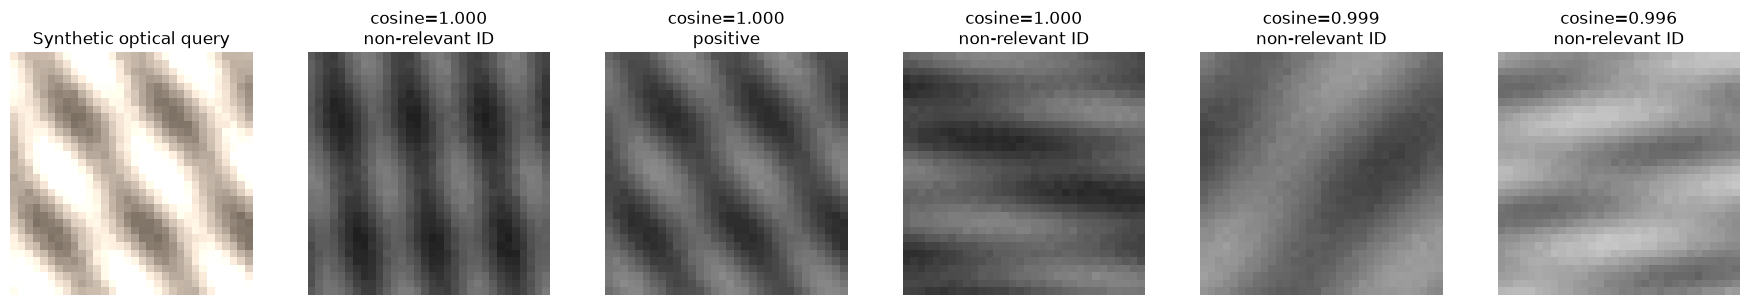

**Observed:** 3/8 optical-to-SAR queries missed their exact positive at rank 1. Shown query positive rank: **2**. These are synthetic fixture results only.

In [3]:
index = CosineIndex(sar_vectors, ids, metadata)
ranks = paired_ranks(index.similarities(optical_vectors), ids, ids)
failed = np.flatnonzero(ranks > 1)
query_i = int(failed[0]) if len(failed) else 0
hits = index.search(optical_vectors[query_i], 5)[0]
display(pd.DataFrame([{ "rank": rank, "id": hit["id"], "cosine": hit["score"], "relevant": hit["id"] == ids[query_i], "block": hit["metadata"]["block_id"], "land_cover": hit["metadata"]["land_cover"] } for rank, hit in enumerate(hits, 1)]))
lookup = {pair_id: i for i, pair_id in enumerate(ids)}
_, query_optical, mask = load_pair_arrays(test_frame.iloc[query_i])
fig, axes = plt.subplots(1, len(hits)+1, figsize=(3*(len(hits)+1), 3))
rgb = np.moveaxis(np.clip(query_optical[[2,1,0]] * 2.5, 0, 1), 0, -1)
rgb[~mask] = 0
axes[0].imshow(rgb); axes[0].set_title("Synthetic optical query")
for ax, hit in zip(axes[1:], hits):
    sar, _, valid = load_pair_arrays(test_frame.iloc[lookup[hit["id"]]])
    ax.imshow(np.ma.array(sar[0], mask=~valid), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"cosine={hit['score']:.3f}\n{'positive' if hit['id'] == ids[query_i] else 'non-relevant ID'}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
display(Markdown(f"**Observed:** {len(failed)}/{len(ids)} optical-to-SAR queries missed their exact positive at rank 1. Shown query positive rank: **{ranks[query_i]}**. These are synthetic fixture results only."))